# Guidance strength

**How strongly generated child rows follow the parent-group classifier. Stronger guidance may improve relationships but reduce diversity.**

**First prerequisite:** prepare the account sample, then complete [01_baseline.ipynb](../01_baseline.ipynb). No historical experiment runs or original model checkpoints are used here.

**Work required:** Generation only after the baseline; reuse its clustering, diffusion, and classifiers.

The generator's guidance classifiers predict parent groups. The separate overdraft evaluator stays fixed. You run this notebook yourself.

[Instructions and index](../../README.md) · [Final comparison](../02_all_experiments.ipynb) · [Research log](../../docs/PROGRESS.md)

In [1]:
import os
import sys
from pathlib import Path

import pandas as pd
import yaml
from IPython.display import Image
from IPython.display import display as show


ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
os.environ.setdefault("MPLCONFIGDIR", "/tmp/transaction-evaluation-matplotlib")
MULTI_TABLE = ROOT / "implementations/tabular_data/multi_table"

from implementations.tabular_data.multi_table.evaluation.transaction_evaluation import evaluate_saved_runs
from implementations.tabular_data.multi_table.experiments.dataset_settings import DATA_DIR as DEFAULT_DATA_DIR
from implementations.tabular_data.multi_table.experiments.tuning import (
    DEFAULT_EXPERIMENT_ROOT,
    DEFAULT_REPORT_ROOT,
    PRESETS,
    base_config,
    completed_runs,
    make_trials,
    preview_trials,
    run_trials,
)


## 1. Settings — keep the baseline fixed

Use the `.venv` kernel. Start with one training/sampling seed and a short candidate list. Keep `RUN_NEW_TRIALS = False` to preview or evaluate completed results. Enable it yourself on a GPU to run a sweep.

The baseline parameter value is included automatically even if you narrow `VALUES`; duplicates are removed. All other settings match the baseline notebook. Keep its input data, root, full sample scale, and base settings fixed. Candidate values are starting experiments, not proven optimal choices.

In [2]:
EXPERIMENT = "guidance"
RUN_NEW_TRIALS = False
SAMPLING_SEEDS = [42, 43, 44]
TRAINING_SEEDS = [42]
# Edit dataset_settings.py once to switch every notebook, or override here.
DATA_DIR = DEFAULT_DATA_DIR
EXPERIMENT_ROOT = DEFAULT_EXPERIMENT_ROOT
OUTPUT_ROOT = DEFAULT_REPORT_ROOT
BASE = base_config(fresh_training=True)
PARAMETER, DEFAULT_VALUES = PRESETS[EXPERIMENT]
VALUES = list(DEFAULT_VALUES)  # Narrow this list for the first sweep.

print(f"Selected processed dataset: {DATA_DIR}")


Selected processed dataset: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/data/berka_accounts_500_seed42


/home/armoso/repo/vector-bootcamp-synthetic-data/.venv/lib64/python3.12/site-packages/torch/jit/_script.py:1491: FutureWarning: `torch.jit.script` is deprecated. Please switch to `torch.compile` or `torch.export`.
  warnings.warn(


## 2. Preview and check the baseline

This creates no models or synthetic data. Stage IDs show logical reuse groups; completed stages are checked during execution. A model set covers all nine parent/table relations.

The baseline is included for each requested seed pair. Vary sampling seeds later to test generation variability; vary training seeds separately to test model variability.

In [3]:
TRIALS = make_trials(
    BASE, PARAMETER, VALUES, sampling_seeds=SAMPLING_SEEDS,
    training_seeds=TRAINING_SEEDS, include_baseline=True,
)
PLAN = preview_trials(TRIALS)
show(PLAN.drop(columns="config"))
COUNTS = PLAN[["cluster", "diffusion", "model", "sample"]].nunique()
print(f"Planned configurations/generations: {COUNTS['sample']} (includes the baseline).")
print(f"Logical sets before cache lookup: {COUNTS['cluster']} clustering, "
      f"{COUNTS['diffusion']} diffusion, {COUNTS['model']} classifier.")
BASELINE_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=[BASE]) if DATA_DIR.is_dir() else []
if BASELINE_DIRS:
    print("Baseline found. Matching completed stages will be reused.")
else:
    print("No completed baseline yet. Run 01_baseline.ipynb before enabling this sweep.")


,cluster,diffusion,model,sample,training_seed,sampling_seed,guidance,clusters
0,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,013d0db4bc897faae5dc,42,42,1.0,50
1,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,78b8e56d6a64374281cb,42,43,1.0,50
2,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,6c2cdf5cf31184080238,42,44,1.0,50
3,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,60197a51fac302bf050e,42,42,0.0,50
4,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,f6762437c6f5b0dfe006,42,43,0.0,50
5,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,5ffa0b5b222889e7f109,42,44,0.0,50
6,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,25860f5891374e07521e,42,42,0.5,50
7,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,260ace32e38d4a6abc7b,42,43,0.5,50
8,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,195cc272f600942f0fd1,42,44,0.5,50
9,853598978302b1623751,f36140014b1759667004,f687bb4d5e41b2323d1c,11e2257bb49513b18cb2,42,42,2.0,50


Planned configurations/generations: 15 (includes the baseline).
Logical sets before cache lookup: 1 clustering, 1 diffusion, 1 classifier.
Baseline found. Matching completed stages will be reused.


## 3. Run this sweep on GPU

This step requires the completed baseline and your `RUN_NEW_TRIALS = True` setting. Compatible baseline stages are reused. Run one generating notebook at a time; retain the same experiment root across notebooks. Inspect `status.json` if a stage fails before choosing a fresh root to retry.

In [4]:
NEW_RUN_DIRS = []
if RUN_NEW_TRIALS:
    if not BASELINE_DIRS:
        raise ValueError("Create the reference run in 01_baseline.ipynb before starting this sweep.")
    EXPERIMENT_ROOT.mkdir(parents=True, exist_ok=True)
    PLAN.drop(columns="config").to_csv(EXPERIMENT_ROOT / f"plan_{EXPERIMENT}.csv", index=False)
    NEW_RUN_DIRS = run_trials(TRIALS, DATA_DIR, EXPERIMENT_ROOT, device="cuda")
    show(pd.DataFrame({"saved_run": [str(path) for path in NEW_RUN_DIRS]}))
else:
    print("Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.")


Preview only. Enable RUN_NEW_TRIALS yourself after completing the baseline.


## 4. Evaluate completed results on CPU

A single real-trained overdraft detector evaluates the baseline and completed variants in this call. An early preview may show just the baseline; incomplete sweeps are not presented as complete comparisons.

Compare event counts, AP/prevalence/uncertainty, overall and overdraft-only distributions, account integrity, and chronology. A high raw synthetic AP alone does not establish the best data.

The same report also scores all 8 tables and 8 parent/child edges: column distributions, missing/unknown values, within/cross-table relationships, cardinalities, and PK/FK integrity. It checks client/account combinations through `disp`. The full-table and overdraft score groups remain separate; no combined winner score is used.

Evaluating 0239084f8447ca75b05b
Evaluating 06cdfa870b60f053dee8
Evaluating 1e7b4f88820f85c0c8b1
Evaluating 40a21f68cd972adc40d7
Evaluating 458e018a99a29d9ff7e5
Evaluating 48ac7b77b081810d9e94
Evaluating 50f8c93d050c215f3299
Evaluating 75e0a6b26f685e79b3b3
Evaluating 9bd3f5f7fa33a9734c17
Evaluating 9c40be997c242aebabef
Evaluating e0c3e652acdf825cfe3c
Evaluating e2cf71fc9b2cb2bdcc74
Evaluating e5e92e553833253d3a3f
Evaluating ebd0250429226a360923
Evaluating ff1084d8eb3f00f04425


,parameter_value,average_precision,average_precision_low,average_precision_high,standardized_ap,overdraft_prevalence,transaction_ks,transaction_tvd,overdraft_numerical_ks,synthetic_transaction_before_account_rate
dataset,,,,,,,,,,
real_test,NaN,0.2422,0.0005,0.3606,0.2422,0.0017,NaN,NaN,NaN,NaN
0239084f8447ca75b05b,0.0,0.0164,0.0149,0.0181,0.0056,0.0050,0.0482,0.0236,0.7128,0.2178
06cdfa870b60f053dee8,4.0,0.0196,0.0174,0.0228,0.0047,0.0071,0.1298,0.0301,0.5168,0.2215
1e7b4f88820f85c0c8b1,2.0,0.0157,0.0140,0.0174,0.0050,0.0053,0.0795,0.0239,0.6188,0.1583
40a21f68cd972adc40d7,1.0,0.0159,0.0139,0.0177,0.0054,0.0050,0.0620,0.0232,0.6573,0.1697
458e018a99a29d9ff7e5,2.0,0.0158,0.0141,0.0174,0.0050,0.0054,0.0751,0.0231,0.6203,0.1996
48ac7b77b081810d9e94,2.0,0.0151,0.0134,0.0168,0.0047,0.0054,0.0755,0.0231,0.5726,0.1994
50f8c93d050c215f3299,0.0,0.0166,0.0150,0.0182,0.0053,0.0053,0.0487,0.0240,0.6548,0.1958
75e0a6b26f685e79b3b3,4.0,0.0169,0.0150,0.0193,0.0042,0.0069,0.1251,0.0302,0.4828,0.2192


Detailed report: /home/armoso/repo/vector-bootcamp-synthetic-data/implementations/tabular_data/multi_table/results/experiments/transaction_overdraft_from_scratch/be458f4c5ed13f61


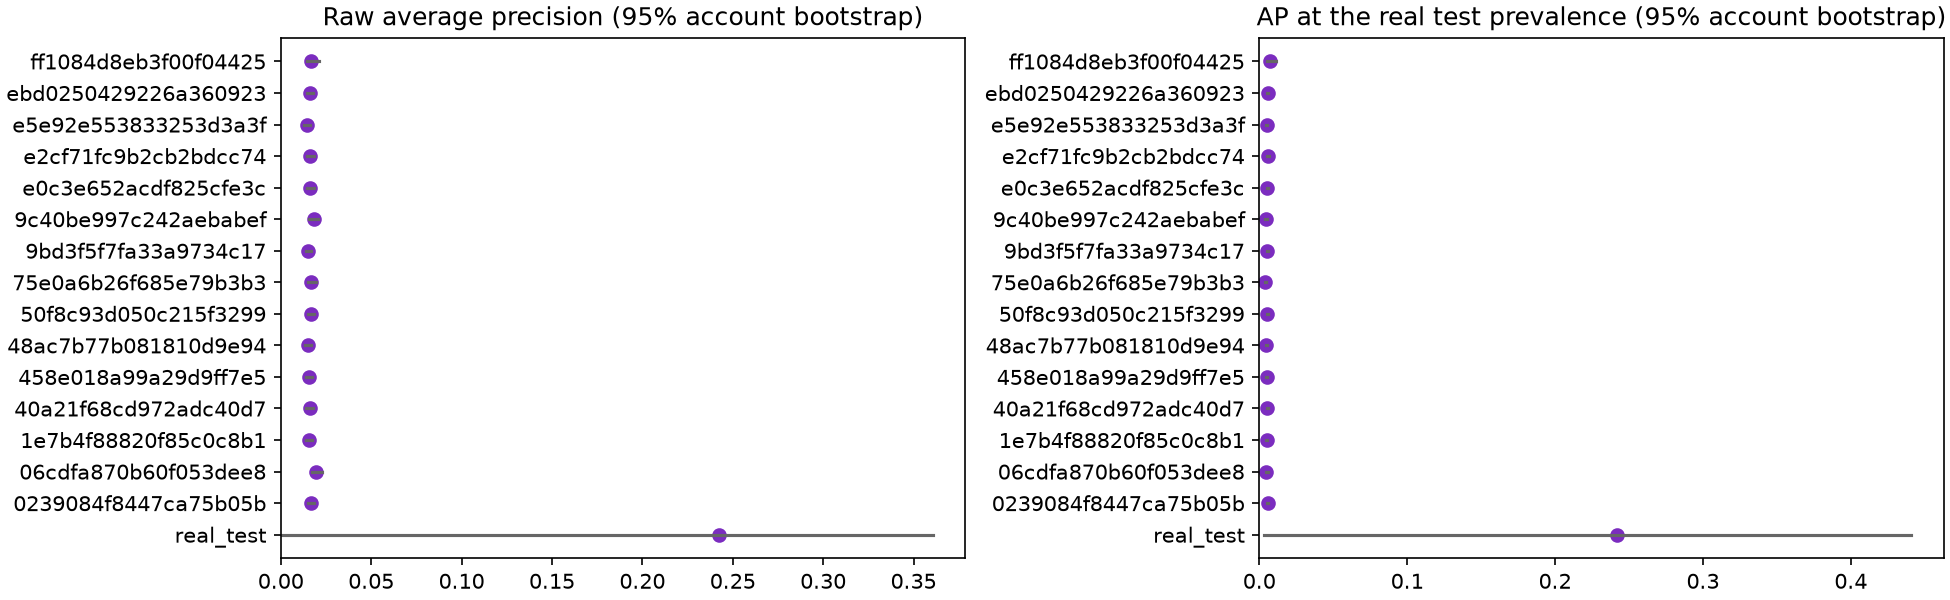

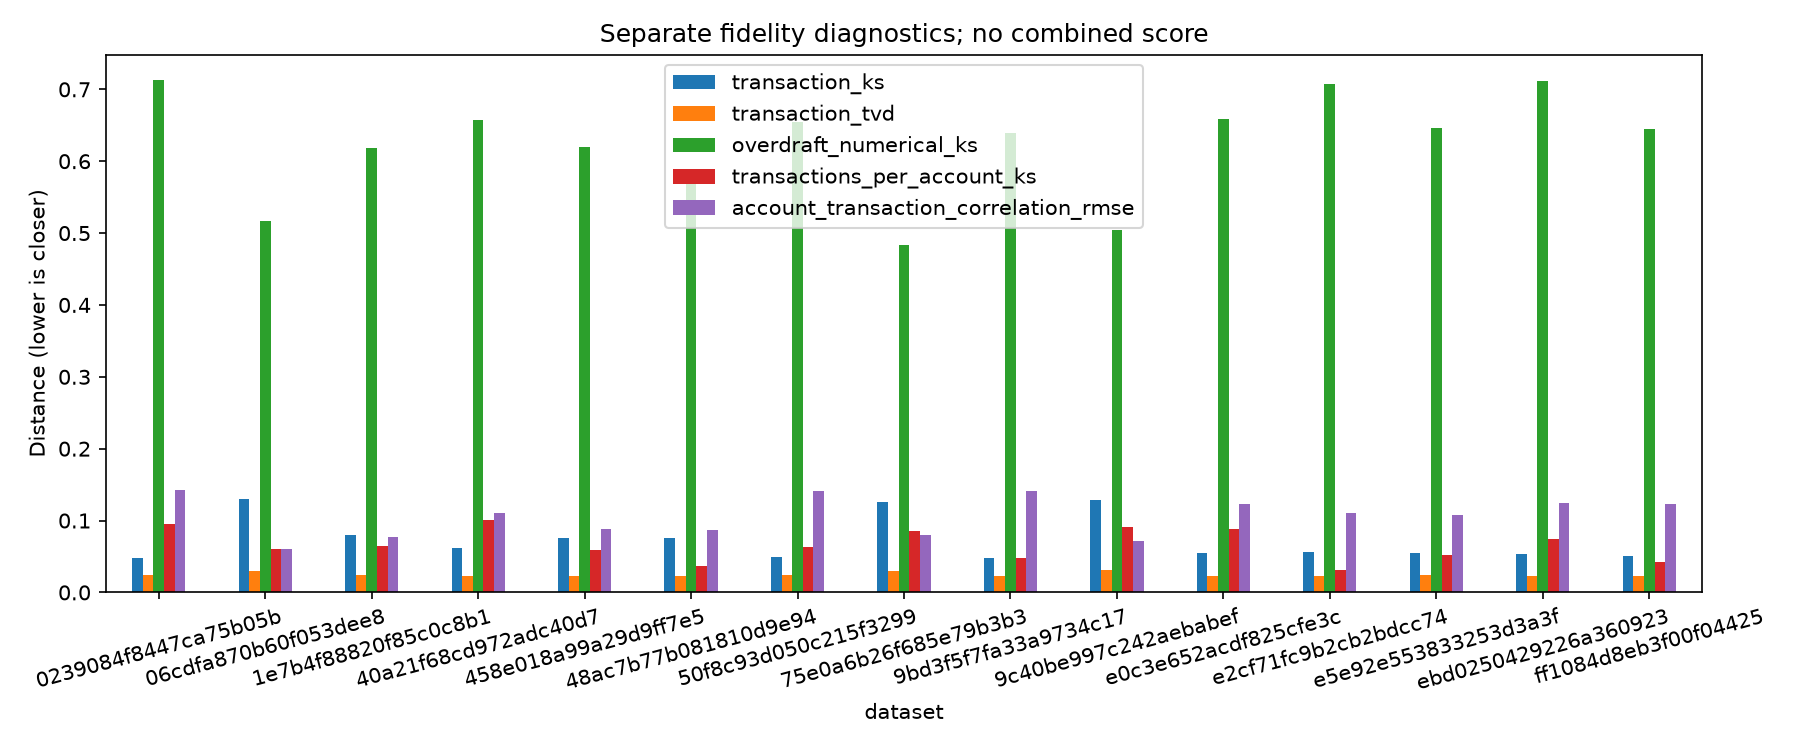

Completed 15 of 15 requested seed/configuration pairs.
Full multi-table quality — separate from overdraft transfer:


,all_table_count,all_edge_count,all_table_numerical_ks,all_table_categorical_tvd,all_cardinality_ks,all_relationship_correlation_rmse,all_min_fk_valid_rate,all_min_pk_unique_rate,multi_parent_correlation_rmse,multi_parent_joint_categorical_tvd,all_undefined_distribution_columns,all_undefined_correlation_pairs
dataset,,,,,,,,,,,,
0239084f8447ca75b05b,8.0,8.0,0.1079,0.1006,0.0959,NaN,1.0,1.0,0.0399,0.1641,0.0,2.0
06cdfa870b60f053dee8,8.0,8.0,0.1498,0.1270,0.0943,NaN,1.0,1.0,0.0345,0.2297,0.0,2.0
1e7b4f88820f85c0c8b1,8.0,8.0,0.1240,0.1217,0.0781,NaN,1.0,1.0,0.0272,0.1931,0.0,2.0
40a21f68cd972adc40d7,8.0,8.0,0.1104,0.0992,0.0812,NaN,1.0,1.0,0.0345,0.1600,0.0,2.0
458e018a99a29d9ff7e5,8.0,8.0,0.1342,0.1291,0.0896,NaN,1.0,1.0,0.0285,0.1921,0.0,2.0
48ac7b77b081810d9e94,8.0,8.0,0.1200,0.0983,0.0591,NaN,1.0,1.0,0.0066,0.1600,0.0,2.0
50f8c93d050c215f3299,8.0,8.0,0.1254,0.0932,0.0824,NaN,1.0,1.0,0.0306,0.1454,0.0,2.0
75e0a6b26f685e79b3b3,8.0,8.0,0.1400,0.1008,0.0715,NaN,1.0,1.0,0.0108,0.1739,0.0,2.0
9bd3f5f7fa33a9734c17,8.0,8.0,0.0935,0.1145,0.0573,NaN,1.0,1.0,0.0135,0.1481,0.0,2.0


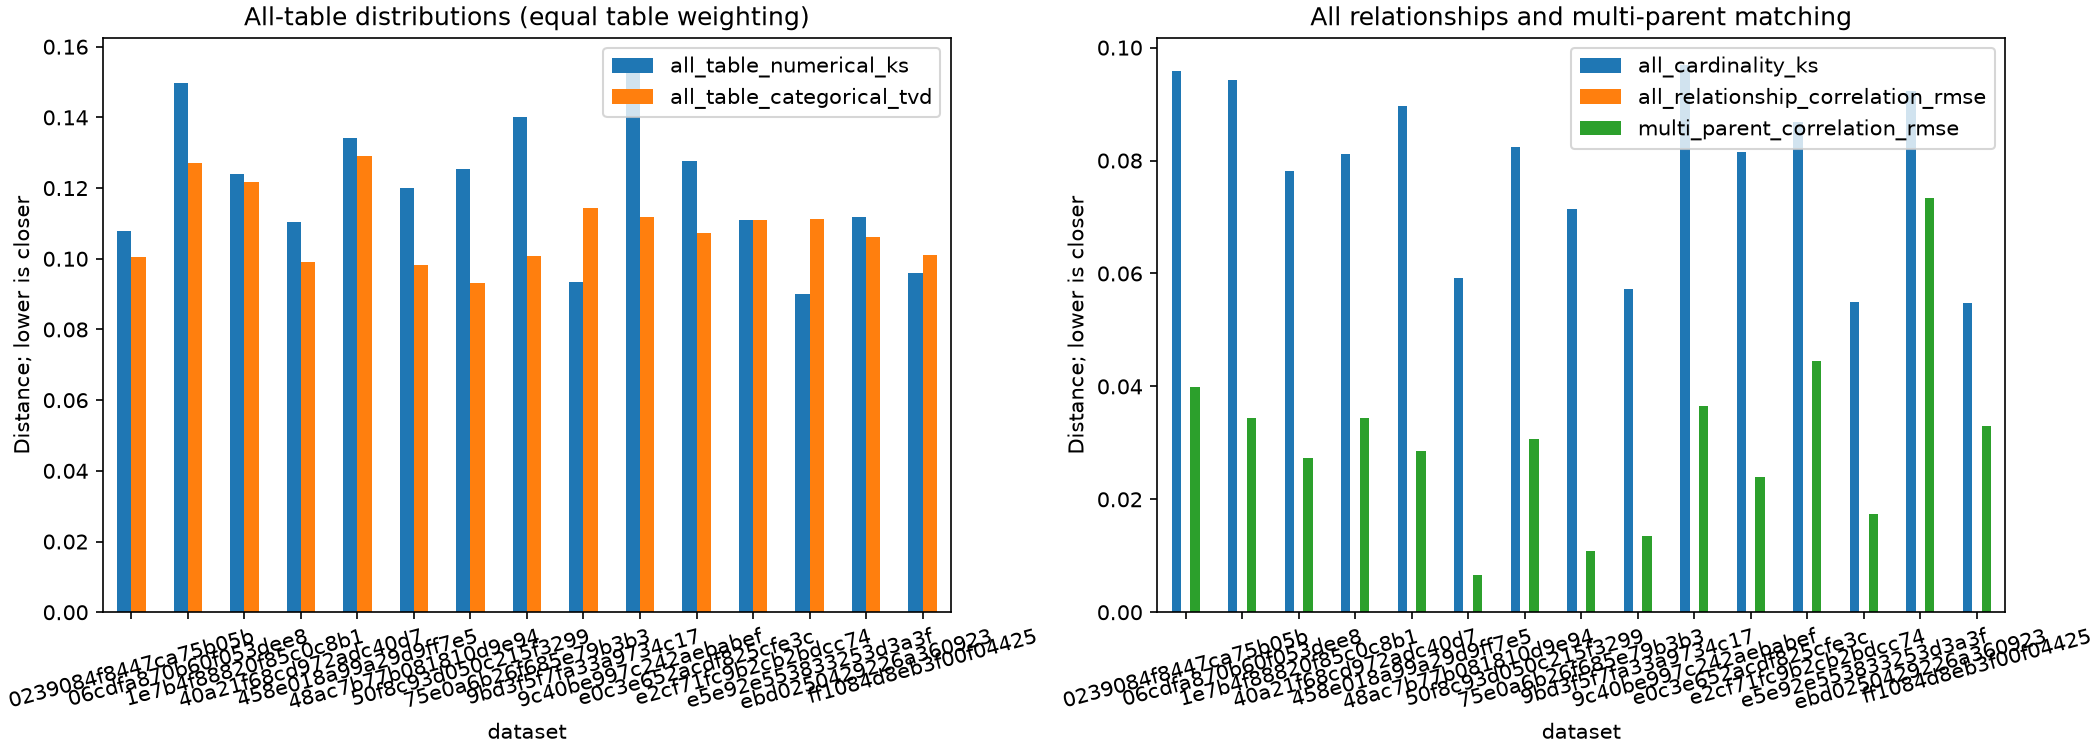

In [5]:
RUN_DIRS = completed_runs(DATA_DIR, EXPERIMENT_ROOT, configs=TRIALS) if DATA_DIR.is_dir() else []
comparison = None
REPORT_DIR = None
if RUN_DIRS:
    comparison, REPORT_DIR = evaluate_saved_runs(DATA_DIR, RUN_DIRS, OUTPUT_ROOT, bootstrap_repetitions=200)
    section, field = PARAMETER.split(".")
    parameter_values = {}
    for run in RUN_DIRS:
        saved = yaml.safe_load((run / "config.yaml").read_text())
        parameter_values[run.name] = str(saved[section][field])
    comparison.insert(0, "parameter_value", pd.Series(parameter_values))
    TRANSFER_AND_QUALITY = [
        "average_precision", "average_precision_low", "average_precision_high",
        "standardized_ap", "overdraft_prevalence", "transaction_ks", "transaction_tvd",
        "overdraft_numerical_ks", "synthetic_transaction_before_account_rate",
    ]
    show(comparison[["parameter_value", *TRANSFER_AND_QUALITY]].round(4))
    print(f"Detailed report: {REPORT_DIR}")
    show(Image(filename=str(REPORT_DIR / "transfer_intervals.png")))
    show(Image(filename=str(REPORT_DIR / "quality_comparison.png")))
    print(f"Completed {len(RUN_DIRS)} of {len(TRIALS)} requested seed/configuration pairs.")
else:
    print("No completed results for this experiment. Start with 01_baseline.ipynb.")

if comparison is not None:
    FULL_TABLE_COLUMNS = [
        "all_table_count", "all_edge_count", "all_table_numerical_ks", "all_table_categorical_tvd",
        "all_cardinality_ks", "all_relationship_correlation_rmse", "all_min_fk_valid_rate",
        "all_min_pk_unique_rate", "multi_parent_correlation_rmse", "multi_parent_joint_categorical_tvd",
        "all_undefined_distribution_columns", "all_undefined_correlation_pairs",
    ]
    print("Full multi-table quality — separate from overdraft transfer:")
    show(comparison.loc[comparison.index != "real_test", FULL_TABLE_COLUMNS].round(4))
    show(Image(filename=str(REPORT_DIR / "multi_table_quality.png")))


## 5. Conclusion — guidance sweep (2026-11-12)

**Decision: keep guidance 1 as the baseline. 0 and 0.5 are equivalent to it within noise; reject 2 and 4. Guidance does not fix the main failures.**

**Setup:** guidance 0, 0.5, 1, 2, 4 × sampling seeds 42/43/44 (15 runs), all reusing one trained model set (training seed 42), sampling batch 8192. Only guidance changes, so this is a clean comparison, but conditional on that one trained model. Values are mean ± sd over the 3 sampling seeds.

| Guidance | Standardized AP ↑ | ROC-AUC ↑ | Overdraft prevalence | Transaction KS ↓ | Overdraft-only KS ↓ | Account→trans corr. RMSE ↓ | Accounts ever overdrawn | Transactions before opening |
| --- | ---: | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| 0 | 0.0054 ± 0.0002 | 0.769 ± 0.006 | 0.51% | 0.048 | 0.669 | 0.141 | 65.7% | 21.3% |
| 0.5 | 0.0060 ± 0.0009 | 0.771 ± 0.003 | 0.50% | 0.053 | 0.672 | 0.124 | 64.4% | 19.5% |
| **1 (baseline)** | 0.0054 ± 0.0003 | 0.763 ± 0.007 | 0.49% | 0.057 | 0.670 | 0.109 | 62.6% | 18.9% |
| 2 | 0.0049 ± 0.0002 | 0.737 ± 0.005 | 0.54% | 0.077 | 0.604 | 0.084 | 62.4% | 18.6% |
| 4 | 0.0044 ± 0.0003 | 0.716 ± 0.009 | 0.70% | 0.128 | 0.502 | 0.071 | 61.8% | 21.2% |

**Real reference:** test AP 0.2422, ROC-AUC 0.8722; overdraft prevalence 0.21%; 5.6% of accounts ever overdrawn; 0% of transactions before opening.

- **Guidance trades overall realism for parent–child fit.** From 0 to 4, transactions follow their account more closely (correlation RMSE 0.141 → 0.071) and overdraft-only distributions improve (KS 0.669 → 0.502). But overall transaction KS worsens (0.048 → 0.128), card KS worsens (0.106 at 1 → 0.307 at 4), overdrafts become too frequent (0.70% vs real 0.21%), and transfer drops (ROC-AUC 0.769 → 0.716).
- **0, 0.5 and 1 are indistinguishable on transfer.** Their standardized AP differences are within one sd. 0.5 has the highest mean, but not reliably.
- **No guidance value fixes the main failures.** 62–66% of accounts ever overdraw (real 5.6%), and 19–21% of transactions come before account opening (real 0%).
- **The transfer gap is about 40×:** standardized AP 0.004–0.006 vs real 0.2422.
- **Keys are valid in all 15 runs** (minimum FK validity and PK uniqueness = 1.0) for this trained model. Other training seeds produced orphan cards; see [PROGRESS.md](../../docs/PROGRESS.md).

**Caveat: this sweep used one trained model, and it was the best of three.** In the training-seed check, the training-seed-42 baseline scored ROC-AUC 0.769, versus 0.614 and 0.653 for seeds 43 and 44. These guidance conclusions hold for this model; they were not repeated on others.

**Change since the 2026-10-29 sweep (other machine):** the cohort and real-test scores are identical, but the retrained baseline behaves differently. Accounts overdrawn rose from 45.8% to 62.6%, prevalence from 0.31% to 0.49%, and ROC-AUC from 0.625 to 0.763. The training-seed check explains this. Across training seeds the baseline spans ROC-AUC 0.614–0.769, prevalence 0.29–0.48%, and accounts overdrawn 43.9–58.1%, and every 2026-10-29 value falls inside those ranges. Retraining noise, not the sampling-batch change, is the likely cause.

**Next:** stop guidance tuning. The main failures need a data-representation change, not a guidance setting.

Report: [comparison.csv](../../../results/experiments/transaction_overdraft_from_scratch/be458f4c5ed13f61/comparison.csv) · [transfer intervals](../../../results/experiments/transaction_overdraft_from_scratch/be458f4c5ed13f61/transfer_intervals.png) · [full-table quality](../../../results/experiments/transaction_overdraft_from_scratch/be458f4c5ed13f61/multi_table_quality.png)